In [1]:
# ============================================================
# CELL 1 — imports, hyperparameters, setup
# ============================================================

from __future__ import annotations

from pathlib import Path
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

from general_ga import GA, GAConfig, VarSpec

from utils import (
    EMCartPoleConfig,
    validate_config,
    validate_population,
    evaluate_population,
    evaluate_single_genome,
    trace_single_episode,
    save_training_checkpoint,
    load_training_checkpoint,
    install_population_in_ga,
    write_history_csv,
    top_percentile_mean,
    plot_training,
    plot_automaton_trace,
    make_cartpole_mp4,
    print_eval_report,
)


# ---------------------------------------------------------------------
# Run controls
# ---------------------------------------------------------------------

RESUME_FROM = None

SEED = 0
TARGET_GEN = 70
SAVE_EVERY = 5
LIVE_PLOT = True

RUN_TRAINING = True
RUN_BATCH_EVAL = True
RUN_VISUALIZATION = True


# ---------------------------------------------------------------------
# Experiment hyperparameters
# ---------------------------------------------------------------------

A = 120

CFG_KWARGS = dict(
    L=19,
    T=30,
    dt=0.1,
    gamma=0.03,
    invalid_threshold=50.0,
    boundary_mode="reflect",  # "wrap" | "reflect" | "zero"

    input_cells=(3, 6, 12, 15),
    output_cell=9,
    threshold=0.05,

    F_max=10.0,
    max_steps=800,

    init_mode="boundary_mixture",
    boundary_prob=0.7,
    boundary_x_low=1.8,
    boundary_x_high=2.2,
    center_x_range=1.5,

    init_x_range=1.5,
    init_dx_range=0.1,
    init_theta_range=0.1,
    init_dtheta_range=0.1,

    fitness_std_penalty=0.06,

    train_rollouts=100,
    eval_rollouts=200,
)


# ---------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------

def make_run_dir(root: str | Path = "runs", prefix: str = "continuous_em1d") -> Path:
    path = Path(root) / time.strftime(f"{prefix}_%Y%m%d_%H%M%S")
    path.mkdir(parents=True, exist_ok=True)
    return path


def make_var_specs(A: int, cfg: EMCartPoleConfig) -> list[VarSpec]:
    return [
        VarSpec(
            name="a",
            dtype="float32",
            shape=(A, 3),
            trainable=True,
            init_mode="uniform",
            min_val=-2.0,
            max_val=2.0,
            mut_type="additive",
            adaptive_mutation_scale=True,
            mut_prob=0.1,
            sigma_base=0.04,
            crossover_prob=0.05,
        ),
        VarSpec(
            name="s",
            dtype="float32",
            shape=(A, cfg.L),
            trainable=False,
            init_mode="constant",
            min_val=-float(cfg.invalid_threshold),
            max_val=float(cfg.invalid_threshold),
            const_val=0.0,
            mut_type="none",
            adaptive_mutation_scale=True,
            mut_prob=0.0,
            sigma_base=0.0,
            crossover_prob=0.0,
        ),
    ]


def per_individual_scalar_count(var_specs: list[VarSpec], *, trainable_only: bool) -> int:
    total = 0
    for spec in var_specs:
        if trainable_only and not spec.trainable:
            continue
        total += int(np.prod(spec.shape[1:]))
    return total


def make_selected_metadata(
    *,
    pop: dict[str, np.ndarray],
    metrics: dict,
    fitness: np.ndarray,
    selected_idx: int,
    gen: int,
) -> dict:
    return {
        "kind": "latest_generation_selected",
        "gen": int(gen),
        "selected_idx": int(selected_idx),
        "fitness": float(fitness[selected_idx]),

        "mean_return": float(metrics["mean_return_by_genome"][selected_idx]),
        "std_return": float(metrics["std_return_by_genome"][selected_idx]),

        "random_action_rate": float(metrics["random_action_rate_by_genome"][selected_idx]),
        "mean_abs_output": float(metrics["mean_abs_output_by_genome"][selected_idx]),
        "mean_state_norm": float(metrics["mean_state_norm_by_genome"][selected_idx]),
        "invalid_rate": float(metrics["invalid_rate_by_genome"][selected_idx]),
        "finite_rate": float(metrics["finite_rate_by_genome"][selected_idx]),
        "mean_internal_steps": float(metrics["mean_internal_steps_by_genome"][selected_idx]),

        "a": pop["a"][selected_idx].astype(float).tolist(),
        "s": pop["s"][selected_idx].astype(float).tolist(),
    }


def load_latest_selected(run_dir: Path, in_memory_selected: dict | None) -> dict:
    if in_memory_selected is not None:
        return in_memory_selected

    ckpt_path = run_dir / "latest_ready.npz"
    if not ckpt_path.exists():
        raise FileNotFoundError(f"Could not find checkpoint: {ckpt_path}")

    ckpt = load_training_checkpoint(ckpt_path)
    selected = ckpt["metadata"].get("selected")

    if selected is None:
        raise RuntimeError("Checkpoint metadata does not contain a latest selected individual.")

    return selected


def save_latest_ready(
    *,
    run_dir: Path,
    pop: dict[str, np.ndarray],
    cfg: EMCartPoleConfig,
    ga_cfg: GAConfig,
    history: list[dict],
    next_gen: int,
    completed_gen: int,
    latest_selected: dict | None,
) -> Path:
    return save_training_checkpoint(
        run_dir / "latest_ready.npz",
        pop=pop,
        cfg=cfg,
        ga_cfg=ga_cfg,
        history=history,
        next_gen=next_gen,
        completed_gen=completed_gen,
        metadata={
            "kind": "latest_ready",
            "saved_after_reproduction": True,
            "selected": latest_selected,
        },
    )


# ---------------------------------------------------------------------
# Initialize or resume
# ---------------------------------------------------------------------

rng = np.random.default_rng(SEED)
latest_selected = None

if RESUME_FROM is None:
    cfg = EMCartPoleConfig(**CFG_KWARGS)
    validate_config(cfg)

    ga_cfg = GAConfig(
        population_size=A,
        elitism=10,
        tournament_k=2,
        bank_max=2000,
        bank_add_every=1,
        immigrants_per_gen=4,
        random_immigrants_per_gen=20,
        eps_adapt=0.03,
        noise_dist="student_t",
        t_df=2.0,
    )

    RUN_DIR = make_run_dir()
    start_gen = 1
    completed_gen = 0
    history = []

    var_specs = make_var_specs(A, cfg)
    ga = GA(ga_cfg, var_specs)
    ga.rng = np.random.default_rng(SEED + 1)
    pop = ga.ask(init=True)

    save_latest_ready(
        run_dir=RUN_DIR,
        pop=pop,
        cfg=cfg,
        ga_cfg=ga_cfg,
        history=history,
        next_gen=start_gen,
        completed_gen=completed_gen,
        latest_selected=latest_selected,
    )

else:
    RESUME_FROM = Path(RESUME_FROM)
    ckpt = load_training_checkpoint(RESUME_FROM)

    cfg = ckpt["cfg"]
    ga_cfg = ckpt["ga_cfg"]
    pop_loaded = ckpt["pop"]

    A = int(pop_loaded["s"].shape[0])
    RUN_DIR = RESUME_FROM.parent

    start_gen = int(ckpt["next_gen"])
    completed_gen = int(ckpt["completed_gen"])
    history = ckpt["history"]
    latest_selected = ckpt["metadata"].get("selected")

    var_specs = make_var_specs(A, cfg)
    ga = GA(ga_cfg, var_specs)
    ga.rng = np.random.default_rng(SEED + 1)
    pop = install_population_in_ga(
        ga,
        pop_loaded,
        generation=max(0, completed_gen),
    )

    print(f"Resuming from {RESUME_FROM}")
    print(f"completed_gen={completed_gen} next_gen={start_gen}")

validate_population(pop, cfg, A)

print("run dir:", RUN_DIR.resolve())
print("seed:", SEED)
print("cfg:", cfg)
print("ga_cfg:", ga_cfg)
print("population keys:", sorted(pop.keys()))
print("s shape:", pop["s"].shape)
print("a shape:", pop["a"].shape)
print("trainable scalars per individual:", per_individual_scalar_count(var_specs, trainable_only=True))
print("total scalars per individual:", per_individual_scalar_count(var_specs, trainable_only=False))
print("start_gen:", start_gen)

run dir: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557
seed: 0
cfg: EMCartPoleConfig(L=19, T=30, dt=0.1, gamma=0.03, invalid_threshold=50.0, boundary_mode='reflect', input_cells=(3, 6, 12, 15), output_cell=9, threshold=0.05, F_max=10.0, max_steps=800, g=9.8, masscart=1.0, masspole=0.1, length=0.5, tau=0.02, x_threshold=2.4, theta_threshold=0.20943951023931953, norm_x=1.0, norm_dx=2.0, norm_theta=0.13962634015954636, norm_dtheta=3.0, init_mode='boundary_mixture', init_x_range=1.5, init_dx_range=0.1, init_theta_range=0.1, init_dtheta_range=0.1, boundary_prob=0.7, boundary_x_low=1.8, boundary_x_high=2.2, center_x_range=1.5, fitness_std_penalty=0.06, train_rollouts=100, eval_rollouts=200)
ga_cfg: GAConfig(population_size=120, elitism=10, bank_max=2000, bank_add_every=1, immigrants_per_gen=4, random_immigrants_per_gen=20, tournament_k=2, eps_adapt=0.03, t_df=2.0, noise_dist='student_t')
population keys: ['a', 's']
s shape: (120, 19)
a shape: (120,

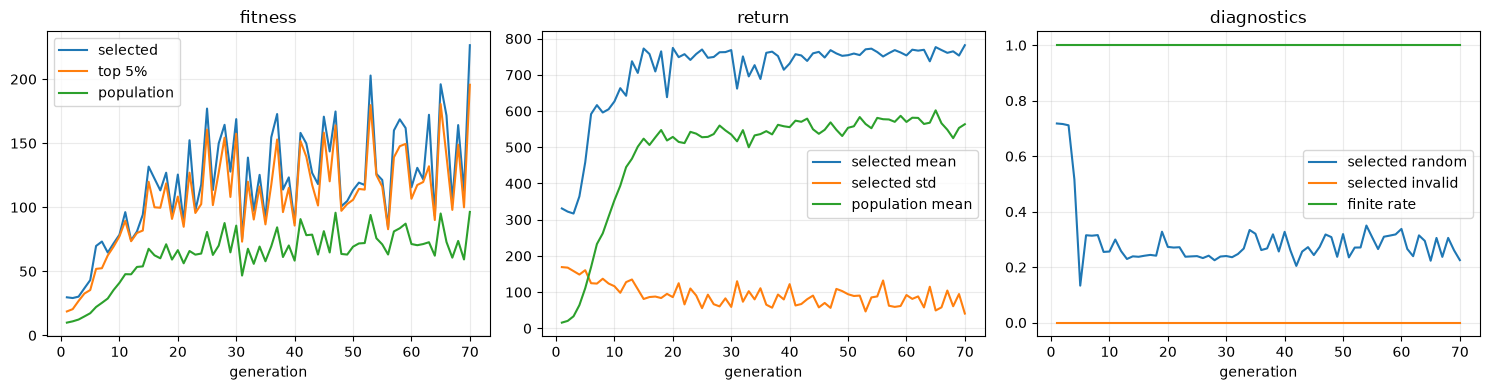

run dir: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557
gen=0070  fit=226.49  top5=195.62  pop=96.36  ret=781.79±40.86  a=(0.779, -0.297, -1.672)  rand=0.225  invalid=0.000  finite=1.000
checkpoint: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557\latest_ready.npz

Done or stopped.
last completed: {'gen': 70, 'selected_fitness': 226.4936981201172, 'top5_fitness': 195.62110900878906, 'population_fitness': 96.35865020751953, 'selected_mean_return': 781.7899780273438, 'selected_std_return': 40.86178970336914, 'population_mean_return': 563.6693115234375, 'population_std_return': 74.10911560058594, 'fitness_std_penalty': 0.06, 'selected_a_l': 0.7789585590362549, 'selected_a_c': -0.29658910632133484, 'selected_a_r': -1.6718199253082275, 'selected_random_action_rate': 0.22524982690811157, 'selected_abs_output': 0.14678125083446503, 'selected_state_norm': 3.560283899307251, 'selected_invalid_rate': 0.0, 'select

In [2]:

# ============================================================
# CELL 2 — training
# ============================================================

last_row = None

if RUN_TRAINING:
    if TARGET_GEN < start_gen:
        print(f"TARGET_GEN={TARGET_GEN} is smaller than start_gen={start_gen}. Nothing to train.")

    try:
        for gen in range(start_gen, TARGET_GEN + 1):
            fitness, metrics, updated_s = evaluate_population(
                pop,
                cfg,
                rng,
                n_rollouts=cfg.train_rollouts,
            )

            # Critical Lamarckian step:
            # sync lifetime-updated internal states before selection/reproduction.
            pop["s"][:] = updated_s

            selected_idx = int(np.argmax(fitness))
            selected_a = pop["a"][selected_idx].copy()

            latest_selected = make_selected_metadata(
                pop=pop,
                metrics=metrics,
                fitness=fitness,
                selected_idx=selected_idx,
                gen=gen,
            )

            row = {
                "gen": int(gen),

                "selected_fitness": float(fitness[selected_idx]),
                "top5_fitness": top_percentile_mean(fitness, 0.05),
                "population_fitness": float(fitness.mean()),

                "selected_mean_return": float(metrics["mean_return_by_genome"][selected_idx]),
                "selected_std_return": float(metrics["std_return_by_genome"][selected_idx]),
                "population_mean_return": float(metrics["population_mean_return"]),
                "population_std_return": float(metrics["population_std_return"]),

                "fitness_std_penalty": float(metrics["fitness_std_penalty"]),

                "selected_a_l": float(selected_a[0]),
                "selected_a_c": float(selected_a[1]),
                "selected_a_r": float(selected_a[2]),

                "selected_random_action_rate": float(metrics["random_action_rate_by_genome"][selected_idx]),
                "selected_abs_output": float(metrics["mean_abs_output_by_genome"][selected_idx]),
                "selected_state_norm": float(metrics["mean_state_norm_by_genome"][selected_idx]),
                "selected_invalid_rate": float(metrics["invalid_rate_by_genome"][selected_idx]),
                "selected_finite_rate": float(metrics["finite_rate_by_genome"][selected_idx]),
                "selected_mean_internal_steps": float(metrics["mean_internal_steps_by_genome"][selected_idx]),

                "mean_random_action_rate": float(metrics["mean_random_action_rate"]),
                "mean_invalid_rate": float(metrics["mean_invalid_rate"]),
                "finite_rate": float(metrics["finite_rate"]),
                "mean_internal_steps": float(metrics["mean_internal_steps"]),
            }

            history.append(row)
            last_row = row
            completed_gen = gen

            write_history_csv(RUN_DIR / "history.csv", history)

            if LIVE_PLOT:
                clear_output(wait=True)
                fig, _ = plot_training(history)
                if fig is not None:
                    display(fig)
                    plt.close(fig)

            print("run dir:", RUN_DIR.resolve())
            print(
                f"gen={gen:04d}  "
                f"fit={row['selected_fitness']:.2f}  "
                f"top5={row['top5_fitness']:.2f}  "
                f"pop={row['population_fitness']:.2f}  "
                f"ret={row['selected_mean_return']:.2f}±{row['selected_std_return']:.2f}  "
                f"a=({row['selected_a_l']:.3f}, {row['selected_a_c']:.3f}, {row['selected_a_r']:.3f})  "
                f"rand={row['selected_random_action_rate']:.3f}  "
                f"invalid={row['selected_invalid_rate']:.3f}  "
                f"finite={row['selected_finite_rate']:.3f}"
            )

            # Reproduce after logging the evaluated/synced population.
            # Non-trainable s is copied from parent A by the corrected GA.
            ga.tell(fitness)
            pop = ga.ask()

            if (gen % SAVE_EVERY == 0) or (gen == TARGET_GEN):
                save_latest_ready(
                    run_dir=RUN_DIR,
                    pop=pop,
                    cfg=cfg,
                    ga_cfg=ga_cfg,
                    history=history,
                    next_gen=gen + 1,
                    completed_gen=gen,
                    latest_selected=latest_selected,
                )
                print("checkpoint:", (RUN_DIR / "latest_ready.npz").resolve())

    except KeyboardInterrupt:
        print("\nTraining interrupted.")
        print("Last completed generation:", completed_gen)
        print("Resume from:", (RUN_DIR / "latest_ready.npz").resolve())

    print("\nDone or stopped.")
    if last_row is not None:
        print("last completed:", last_row)


=== latest selected evaluation ===
n_rollouts               : 200
fitness                  : 81.162125
mean_return              : 749.320007
std_return               : 137.206436
best_return              : 800.000000
min_return               : 54.000000
mean_random_action_rate  : 0.226559
mean_abs_output          : 0.144950
mean_state_norm          : 3.565949
mean_invalid_rate        : 0.000000
finite_rate              : 1.000000
mean_internal_steps      : 30.000000

=== selected parameters ===
source generation: 70
a: [ 0.77895856 -0.2965891  -1.6718199 ]
max |s|: 2.785834789276123

=== experiment record ===
action space : Discrete(2) {'0': 'push left, F = -10.0', '1': 'push right, F = +10.0'}
seed         : {'env_rng_seed': 0, 'ga_rng_seed': 1}
episodes     : {'train_rollouts_per_generation': 100, 'generations': 70, 'population_size': 120, 'eval_rollouts': 200}
reward       : +1 for every valid CartPole step (including the terminating step); invalid CEM1D internal dynamics give no r

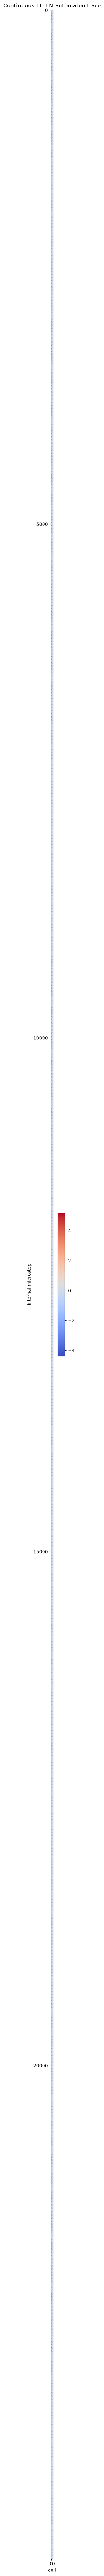

automaton highres png: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557\automaton_trace_highres.png
cartpole mp4: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557\cartpole_latest_trace.mp4


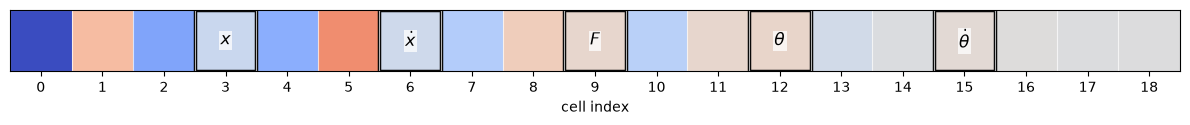

interface/state png: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557\cem1d_interface_state.png


In [3]:

# ============================================================
# CELL 3 — validation / evaluation
# ============================================================

if RUN_BATCH_EVAL:
    selected = load_latest_selected(RUN_DIR, latest_selected)

    eval_s = np.asarray(selected["s"], dtype=np.float32)
    eval_a = np.asarray(selected["a"], dtype=np.float32)

    eval_report = evaluate_single_genome(
        s=eval_s,
        a=eval_a,
        cfg=cfg,
        rng=rng,
        n_rollouts=cfg.eval_rollouts,
    )

    print_eval_report("latest selected evaluation", eval_report)

    print("\n=== selected parameters ===")
    print("source generation:", selected["gen"])
    print("a:", eval_a)
    print("max |s|:", float(np.max(np.abs(eval_s))))

    # ------------------------------------------------------------
    # Experiment record: environment, action space, seed, episodes,
    # reward definition and termination conditions.
    # ------------------------------------------------------------
    import json

    experiment_record = {
        "environment": {
            "name": "CartPole (standard Euler dynamics, Barto et al.)",
            "g": cfg.g,
            "masscart": cfg.masscart,
            "masspole": cfg.masspole,
            "half_pole_length": cfg.length,
            "tau": cfg.tau,
            "max_steps_per_episode": int(cfg.max_steps),
            "init_mode": cfg.init_mode,
            "boundary_prob": cfg.boundary_prob,
            "boundary_x_range": [cfg.boundary_x_low, cfg.boundary_x_high],
            "center_x_range": cfg.center_x_range,
            "init_dx_range": cfg.init_dx_range,
            "init_theta_range": cfg.init_theta_range,
            "init_dtheta_range": cfg.init_dtheta_range,
        },
        "action_space": {
            "type": "Discrete(2)",
            "actions": {"0": f"push left, F = -{cfg.F_max}", "1": f"push right, F = +{cfg.F_max}"},
            "decode_rule": (
                f"z = s[output_cell={cfg.output_cell}]; "
                f"z < -{cfg.threshold} -> left; z > {cfg.threshold} -> right; "
                f"|z| <= {cfg.threshold} -> uniform random action"
            ),
        },
        "observation": {
            "variables": ["x", "x_dot", "theta", "theta_dot"],
            "input_cells": list(cfg.input_cells),
            "normalization": [cfg.norm_x, cfg.norm_dx, cfg.norm_theta, cfg.norm_dtheta],
            "clip": [-4.0, 4.0],
        },
        "reward": {
            "per_step": 1.0,
            "definition": "+1 for every valid CartPole step (including the terminating step); "
                          "invalid CEM1D internal dynamics give no reward and end the episode",
            "max_return": int(cfg.max_steps),
            "fitness": f"mean_return / (1 + {cfg.fitness_std_penalty} * std_return)",
        },
        "termination": {
            "abs_x_greater_than": cfg.x_threshold,
            "abs_theta_greater_than_rad": cfg.theta_threshold,
            "abs_theta_greater_than_deg": float(np.degrees(cfg.theta_threshold)),
            "non_finite_state": True,
            "internal_state_invalid": f"|s| > {cfg.invalid_threshold} or non-finite",
            "truncation_steps": int(cfg.max_steps),
        },
        "seed": {
            "env_rng_seed": int(SEED),
            "ga_rng_seed": int(SEED + 1),
        },
        "episodes": {
            "train_rollouts_per_generation": int(cfg.train_rollouts),
            "generations": int(TARGET_GEN),
            "population_size": int(A),
            "eval_rollouts": int(eval_report["n_rollouts"]),
        },
        "cem1d": {
            "L": int(cfg.L),
            "T": int(cfg.T),
            "dt": cfg.dt,
            "gamma": cfg.gamma,
            "boundary_mode": cfg.boundary_mode,
        },
        "eval_result": {
            k: v for k, v in eval_report.items() if k != "final_internal_state"
        },
        "selected_genome": {
            "gen": int(selected["gen"]),
            "a": eval_a.tolist(),
        },
    }

    record_path = RUN_DIR / "experiment_record.json"
    record_path.write_text(json.dumps(experiment_record, indent=2), encoding="utf-8")

    print("\n=== experiment record ===")
    print("action space :", experiment_record["action_space"]["type"], experiment_record["action_space"]["actions"])
    print("seed         :", experiment_record["seed"])
    print("episodes     :", experiment_record["episodes"])
    print("reward       :", experiment_record["reward"]["definition"])
    print("termination  :", experiment_record["termination"])
    print("saved        :", record_path.resolve())


# ============================================================
# CELL 4 — visualization / trace / paper figures
# ============================================================

if RUN_VISUALIZATION:
    selected = load_latest_selected(RUN_DIR, latest_selected)

    vis_s = np.asarray(selected["s"], dtype=np.float32)
    vis_a = np.asarray(selected["a"], dtype=np.float32)

    trace = trace_single_episode(
        s=vis_s,
        a=vis_a,
        cfg=cfg,
        rng=rng,
    )

    print("\n=== trace ===")
    print("return:", trace["return"])
    print("invalid:", trace["invalid"])
    print("automaton shape:", trace["automaton"].shape)

    fig, ax = plot_automaton_trace(trace, cfg)
    plt.show()

    automaton_png = RUN_DIR / "automaton_trace_highres.png"
    fig.savefig(automaton_png, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print("automaton highres png:", automaton_png.resolve())

    mp4_path = make_cartpole_mp4(
        trace=trace,
        cfg=cfg,
        path=RUN_DIR / "cartpole_latest_trace.mp4",
        fps=30,
    )
    print("cartpole mp4:", mp4_path.resolve())

    # ------------------------------------------------------------
    # Interface/state plot for paper-style visualization
    # ------------------------------------------------------------
    from matplotlib.patches import Rectangle

    s_plot = vis_s.copy()
    L = cfg.L

    fig, ax = plt.subplots(figsize=(12, 2.5))

    v = max(abs(float(s_plot.min())), abs(float(s_plot.max())), 1e-6)

    ax.imshow(
        s_plot[None, :],
        cmap="coolwarm",
        vmin=-v,
        vmax=v,
        interpolation="nearest",
        aspect="equal",
        extent=(-0.5, L - 0.5, 0.5, -0.5),
    )

    ax.set_box_aspect(1 / L)

    for x in np.arange(-0.5, L, 1):
        ax.axvline(x, color="white", lw=0.8, alpha=0.7)
    ax.axhline(-0.5, color="white", lw=0.8, alpha=0.7)
    ax.axhline(0.5, color="white", lw=0.8, alpha=0.7)

    io_labels = {
        cfg.input_cells[0]: r"$x$",
        cfg.input_cells[1]: r"$\dot{x}$",
        cfg.input_cells[2]: r"$\theta$",
        cfg.input_cells[3]: r"$\dot{\theta}$",
        cfg.output_cell: r"$F$",
    }

    for c, lab in io_labels.items():
        ax.add_patch(
            Rectangle(
                (int(c) - 0.5, -0.5),
                1.0,
                1.0,
                fill=False,
                edgecolor="black",
                linewidth=2.5,
            )
        )
        ax.text(
            int(c),
            0.0,
            lab,
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="black",
            bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=1.0),
        )

    ax.set_xticks(np.arange(L))
    ax.set_yticks([])
    ax.set_xlabel("cell index")
    ax.set_xlim(-0.5, L - 0.5)
    ax.set_ylim(0.5, -0.5)

    plt.tight_layout()
    plt.show()

    interface_png = RUN_DIR / "cem1d_interface_state.png"
    fig.savefig(interface_png, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print("interface/state png:", interface_png.resolve())

=== 2-macrostep CEM1D reasoning trace ===
source generation: 70
return: 2
invalid: False
automaton shape: (62, 19)
forces: [-10. -10.]
outputs: [-0.3151546  -0.27017936]
random actions: [False False]


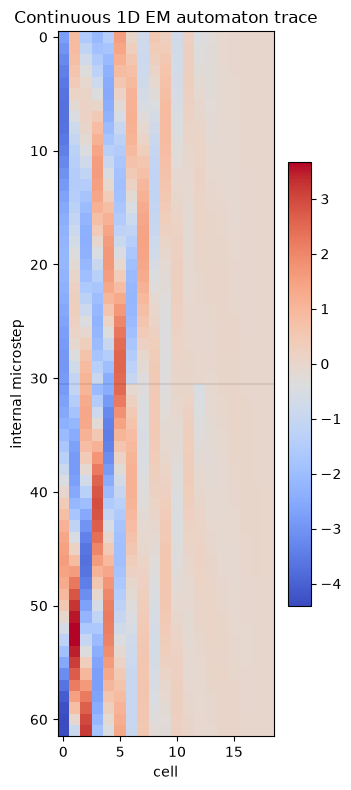

saved reasoning trace: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557\cem1d_reasoning_2_macrosteps.png


In [4]:
# ============================================================
# CELL 4 — short reasoning trace on evaluated genome
# ============================================================

from dataclasses import replace

# Reuse the same latest selected genome used in evaluation.
selected = load_latest_selected(RUN_DIR, latest_selected)

trace_s = np.asarray(selected["s"], dtype=np.float32)
trace_a = np.asarray(selected["a"], dtype=np.float32)

# Trace only the first 2 CartPole macrosteps.
cfg_trace = replace(cfg, max_steps=2)

trace2 = trace_single_episode(
    s=trace_s,
    a=trace_a,
    cfg=cfg_trace,
    rng=rng,
)

print("=== 2-macrostep CEM1D reasoning trace ===")
print("source generation:", selected["gen"])
print("return:", trace2["return"])
print("invalid:", trace2["invalid"])
print("automaton shape:", trace2["automaton"].shape)
print("forces:", trace2["force"])
print("outputs:", trace2["output"])
print("random actions:", trace2["random_action"])

fig, ax = plot_automaton_trace(trace2, cfg_trace)
plt.show()

reasoning_png = RUN_DIR / "cem1d_reasoning_2_macrosteps.png"
fig.savefig(reasoning_png, dpi=300, bbox_inches="tight")
plt.close(fig)

print("saved reasoning trace:", reasoning_png.resolve())

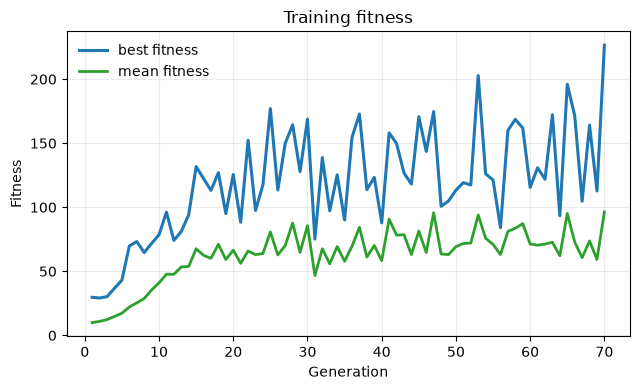

saved: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557\paper_training_fitness.png
saved: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557\paper_training_fitness.pdf


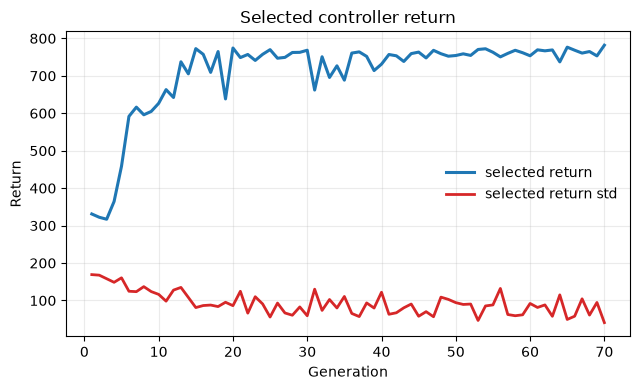

saved: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557\paper_training_return.png
saved: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\continuous_em1d_20261126_100557\paper_training_return.pdf


In [5]:
# ============================================================
# CELL 5 — paper-ready training plots
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

history_path = RUN_DIR / "history.csv"
df = pd.read_csv(history_path)

required_cols = [
    "gen",
    "selected_fitness",
    "population_fitness",
    "selected_mean_return",
    "selected_std_return",
]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns in history.csv: {missing}")

# Fixed simple color choices requested.
BLUE = "#1f77b4"
GREEN = "#2ca02c"
RED = "#d62728"

# ---------------------------------------------------------------------
# Plot 1: selected/best fitness + population mean fitness
# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.5, 4.0))

ax.plot(
    df["gen"],
    df["selected_fitness"],
    color=BLUE,
    linewidth=2.2,
    label="best fitness",
)

ax.plot(
    df["gen"],
    df["population_fitness"],
    color=GREEN,
    linewidth=2.0,
    label="mean fitness",
)

ax.set_xlabel("Generation")
ax.set_ylabel("Fitness")
ax.set_title("Training fitness")
ax.grid(alpha=0.25, linewidth=0.8)
ax.legend(frameon=False)

fig.tight_layout()

fitness_png = RUN_DIR / "paper_training_fitness.png"
fitness_pdf = RUN_DIR / "paper_training_fitness.pdf"

fig.savefig(fitness_png, dpi=300, bbox_inches="tight")
fig.savefig(fitness_pdf, bbox_inches="tight")

plt.show()
plt.close(fig)

print("saved:", fitness_png.resolve())
print("saved:", fitness_pdf.resolve())


# ---------------------------------------------------------------------
# Plot 2: selected return + selected std
# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.5, 4.0))

ax.plot(
    df["gen"],
    df["selected_mean_return"],
    color=BLUE,
    linewidth=2.2,
    label="selected return",
)

ax.plot(
    df["gen"],
    df["selected_std_return"],
    color=RED,
    linewidth=2.0,
    label="selected return std",
)

ax.set_xlabel("Generation")
ax.set_ylabel("Return")
ax.set_title("Selected controller return")
ax.grid(alpha=0.25, linewidth=0.8)
ax.legend(frameon=False)

fig.tight_layout()

return_png = RUN_DIR / "paper_training_return.png"
return_pdf = RUN_DIR / "paper_training_return.pdf"

fig.savefig(return_png, dpi=300, bbox_inches="tight")
fig.savefig(return_pdf, bbox_inches="tight")

plt.show()
plt.close(fig)

print("saved:", return_png.resolve())
print("saved:", return_pdf.resolve())

a: [ 0.77895856 -0.2965891  -1.6718199 ]
T: 12
dt: 0.1
gamma: 0.03
boundary_mode: reflect
invalid: False
rollout shape: (13, 19)
final state: [-3.94146227e-05  4.82508010e-04 -4.24661115e-03  2.66517233e-02
 -1.18511274e-01  3.59636664e-01 -6.70400143e-01  5.02893388e-01
  6.02020919e-01 -1.31870973e+00  1.39251351e-02  7.79640079e-01
  4.66121584e-01  1.40859231e-01  2.70534270e-02  3.59498314e-03
  3.43231019e-04  2.38681914e-05  1.11747329e-06]


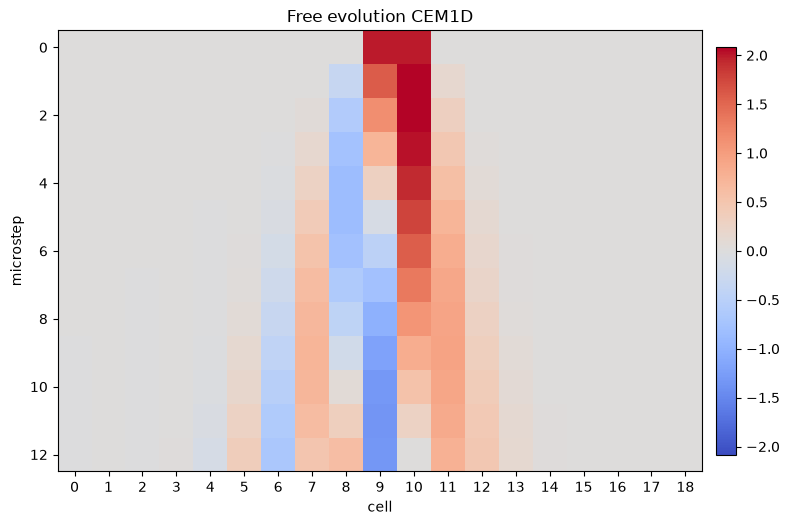

In [6]:
# ============================================================
# CELL 6 — free CEM1D microstep rollout from editable initial state
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Editable initial CEM1D state.
s0 = np.zeros(19, dtype=np.float32)

# Example: uncomment/edit to perturb cells manually.
s0[9] = 2.0
s0[10] = 2.0

# Rule coefficients of the latest selected genome (edit manually if desired).
a = np.asarray(load_latest_selected(RUN_DIR, latest_selected)["a"], dtype=np.float32)

T_free = 12

def valid_state_local(s):
    return bool(
        np.isfinite(s).all()
        and np.max(np.abs(s)) <= float(cfg.invalid_threshold)
    )

def neighbor_arrays_local(s):
    left = np.empty_like(s)
    right = np.empty_like(s)

    left[1:] = s[:-1]
    right[:-1] = s[1:]

    if cfg.boundary_mode == "wrap":
        left[0] = s[-1]
        right[-1] = s[0]
    elif cfg.boundary_mode == "reflect":
        left[0] = s[0]
        right[-1] = s[-1]
    elif cfg.boundary_mode == "zero":
        left[0] = 0.0
        right[-1] = 0.0
    else:
        raise ValueError(f"Unsupported boundary_mode: {cfg.boundary_mode}")

    return left, right

def cem1d_step_local(s, a):
    left, right = neighbor_arrays_local(s)
    ds = (
        a[0] * left
        + a[1] * s
        + a[2] * right
        - float(cfg.gamma) * (s ** 3)
    )
    return (s + float(cfg.dt) * ds).astype(np.float32)

rows = [s0.copy()]
s = s0.copy()
invalid = False

if not valid_state_local(s):
    invalid = True
else:
    for _ in range(T_free):
        candidate = cem1d_step_local(s, a)

        if not valid_state_local(candidate):
            invalid = True
            break

        s = candidate
        rows.append(s.copy())

rollout = np.asarray(rows, dtype=np.float32)

print("a:", a)
print("T:", T_free)
print("dt:", cfg.dt)
print("gamma:", cfg.gamma)
print("boundary_mode:", cfg.boundary_mode)
print("invalid:", invalid)
print("rollout shape:", rollout.shape)
print("final state:", rollout[-1])

fig_w = 8
fig_h = fig_w * (rollout.shape[0] / rollout.shape[1])

fig, ax = plt.subplots(figsize=(fig_w, fig_h))

v = max(float(np.max(np.abs(rollout))), 1e-6)

im = ax.imshow(
    rollout,
    aspect="equal",          # square cells
    interpolation="nearest",
    origin="upper",
    cmap="coolwarm",
    vmin=-v,
    vmax=v,
)

ax.set_xlabel("cell")
ax.set_ylabel("microstep")
ax.set_title("Free evolution CEM1D")
ax.set_xticks(np.arange(cfg.L))

fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
fig.tight_layout()
plt.show()

In [1]:
# ============================================================
# CELL 7 — no-retention 4-parameter linear CartPole baseline
# ============================================================

from pathlib import Path
from linear_cartpole_baseline import main as run_linear_cartpole_baseline

LINEAR_BASELINE_RUN_DIR = (
    Path("runs") / "linear4_no_retention_20261126_140458"
)
run_linear_cartpole_baseline(LINEAR_BASELINE_RUN_DIR)


run dir: C:\Users\Admin\Downloads\em-exp-gol-cem1d-main\cem1d\runs\linear4_no_retention_20261126_140458
seed: {'environment': 0, 'genetic_algorithm': 1, 'final_evaluation': 2}
controller: {'type': 'linear threshold policy', 'parameters': ['w_x', 'w_x_dot', 'w_theta', 'w_theta_dot'], 'parameter_count': 4, 'action_rule': 'score = dot(weights, normalized_observation); score >= 0 selects right, otherwise left', 'retained_internal_state': False}
training: {'population_size': 120, 'generations': 70, 'episodes_per_generation': 100, 'total_training_episodes': 7000, 'evaluation_episodes': 200, 'automaton_L_T': 'not applicable to a 4-parameter linear controller'}
gen=001/70 fitness=58.639 return=263.3±58.2 weights=[0.20499999821186066, -2.808000087738037, 3.7200000286102295, -0.7870000004768372]
gen=002/70 fitness=45.518 return=287.0±88.4 weights=[0.20499999821186066, -2.808000087738037, 3.7200000286102295, -0.7870000004768372]
gen=003/70 fitness=47.848 return=384.0±117.1 weights=[0.172000005841